In [314]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.special import erf, erfinv
from scipy.integrate import quad
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression as LR

In [315]:
X_train=np.load("data/Chest/X.npy")   #load Covid or Gaussian data to change datasets
y_train=np.load("data/Chest/y.npy")


X_train=X_train.reshape(X_train.shape[0], -1)

#Held-out dataset to fit the standard scaler
Nho=100
X_ho=X_train[:Nho]
X_train=X_train[Nho:]; y_train=y_train[Nho:]

#Standard scaler for the real datasets
scaler=StandardScaler()
scaler.fit(X_ho)
X_train=scaler.transform(X_train)
y_train=np.sign(y_train-.5)


idx=np.random.permutation(X_train.shape[0])
X_train=X_train[idx]
y_train=y_train[idx]


In [317]:

d=X_train.shape[1]
n=X_train.shape[0]
Δ=.2

In [318]:
def dl(z,y):   #adatron
    grad=-2*(y*z<0)*np.abs(z)*y
    return grad

In [319]:
def Φ(x):
    return .5*(erf(x/np.sqrt(2))+1)
def G(x):
    return np.exp(-.5*x**2)/np.sqrt(2*np.pi)

def dG(x):
    return -x*np.exp(-.5*x**2)/np.sqrt(2*np.pi)

def phi(z):
    #print(type(z))
    if isinstance(z, np.ndarray): z=z[0]
    term1=-quad(lambda x: x**2*(Φ(-x/np.sqrt(2))-Φ(-z-x/np.sqrt(2))), 0, np.inf)[0]
    term2=np.sqrt(4/np.pi)*(1-np.exp(-z**2/2)+np.sqrt(2*np.pi)*z*Φ(-z))
    res=4/np.sqrt(2*np.pi)*(term1+term2)
    return res


q0=0.1
κ=4*q0**.5*np.abs(erfinv(2*Δ-1))/np.abs(phi(np.sqrt(2)*np.abs(erfinv(2*Δ-1))))

In [321]:


Ntrials=3



RR_P=[]; MM_P=[]; QQ_P=[]
RR_i=[]; MM_i=[]; QQ_i=[]
RR_C=[]; MM_C=[]; QQ_C=[]
RR_C3=[]; MM_C3=[]; QQ_C3=[]
RR_S=[]; MM_S=[]; QQ_S=[]
RR_D=[]; MM_D=[]; QQ_D=[]
RR=[]; MM=[]; QQ=[]

for seed in range(Ntrials):
    
    idx=np.random.permutation(X_train.shape[0])
    X_train=X_train[idx]
    y_train=y_train[idx]

    w0= np.zeros(d)

    #random
    Np=50
    ps=np.linspace(.01, 1, Np)
    
    R_P=[[0] for i in range(Np)]
    M_P=[[0] for i in range(Np)]
    Q_P=[[0] for i in range(Np)]
    w_P=[w0 for k in range(Np)]
    
    
    #b-sampling 
    Nb=50
    bs=np.logspace(-2, 1, Nb)
    R_C=[[0] for i in range(Nb)]
    M_C=[[0] for i in range(Nb)]
    Q_C=[[0] for i in range(Nb)]
    w_C=[w0 for k in range(Nb)]
    
    
    #adaptative b-sampling
    Nb3=50
    betas=np.logspace(-2, 1, Nb3)
    Ks=[0 for i in range(Nb3)]
    R_C3=[[0] for i in range(Nb3)]
    M_C3=[[0] for i in range(Nb3)]
    Q_C3=[[0] for i in range(Nb3)]
    w_C3=[w0 for k in range(Nb3)]
    
    
    #logistic sampling
    Ng=50
    gammas=np.logspace(-2,1, Ng)
    R_S=[[0] for i in range(Ng)]
    M_S=[[0] for i in range(Ng)]
    Q_S=[[0] for i in range(Ng)]
    w_S=[w0 for k in range(Ng)]
    
    
    #AL-perceptron
    Nr=50
    Rs=[2*k+1 for k in range(Nr)]
    R_D=[[0] for i in range(Nr)]
    M_D=[[0] for i in range(Nr)]
    Q_D=[[0] for i in range(Nr)]
    w_D=[w0 for k in range(Nr)]
    Ps=[0 for i in range(Nr)]  #patience
    Ss=[1/d**.5 for i in range(Nr)]  #thresholds
    
    
                
    #Heuristic
    w0=np.random.randn(d)*q0**.5
    R=[0]
    M=[0]
    Q=[0]
    w=w0.copy()


    #inner-margin
    Ni=50
    kappas=np.logspace(-2, 1.7, Ni)
    
    R_i=[[0] for i in range(Ni)]
    M_i=[[0] for i in range(Ni)]
    Q_i=[[0] for i in range(Ni)]
    wi=np.random.randn(d)*q0**.5
    w_i=[wi for k in range(Ni)]
    
    for t in tqdm(range(n)):
        x=X_train[t]
        y=y_train[t]
        xnorm=x/np.linalg.norm(x)
        
        #update random
    
        for i in range(Np):
            switch=np.random.rand()<ps[i]
            error=(y*(w_P[i]@x)<=0)
            regret=Δ*switch+(1-switch)*error
            w_P[i]=w_P[i]+switch*(y*w_P[i]@xnorm<=0)*y*xnorm            
            (R_P[i]).append(R_P[i][-1]+regret)
            (Q_P[i]).append(Q_P[i][-1]+switch)
            (M_P[i]).append(M_P[i][-1]+(1-switch)*error)
    
        
        #update b-sampling
        
        for i in range(Nb):
            switch=np.random.rand()<=bs[i]/(bs[i]+np.abs(w_C[i]@xnorm))
            error=(y*(w_C[i]@x)<=0)
            regret=Δ*switch+(1-switch)*error
            w_C[i]=w_C[i]+switch*(y*w_C[i]@xnorm<=0)*y*xnorm
            (R_C[i]).append(R_C[i][-1]+regret)
            (Q_C[i]).append(Q_C[i][-1]+switch)
            (M_C[i]).append(M_C[i][-1]+(1-switch)*error)
        
        #update adaptative b-sampling
        for i in range(Nb3):
            b=betas[i]*(1+Ks[i])**.5
            switch=np.random.rand()<=b/(b+np.abs(w_C3[i]@xnorm))
            Ks[i]=Ks[i]+switch*(y*w_C3[i]@xnorm<=0)
            error=(y*(w_C3[i]@x)<=0)
            regret=Δ*switch+(1-switch)*error
            w_C3[i]=w_C3[i]+switch*(y*w_C3[i]@xnorm<=0)*y*xnorm
            (R_C3[i]).append(R_C3[i][-1]+regret)
            (Q_C3[i]).append(Q_C3[i][-1]+switch)
            (M_C3[i]).append(M_C3[i][-1]+(1-switch)*error)
        #inner
        for i in range(Ni):
            switch=(np.abs(w_i[i]@xnorm)<=kappas[i]/((t+1)/d))*1
            error=(y*(w_i[i]@xnorm)<=0)
            regret=Δ*switch+(1-switch)*error
            w_i[i]=w_i[i]-switch*dl(w_i[i]@xnorm,y)*xnorm
            R_i[i].append(R_i[i][-1]+regret)
            Q_i[i].append(Q_i[i][-1]+switch)
            M_i[i].append(M_i[i][-1]+(1-switch)*error)
    
    
        #update logistic sampling
        
        for i in range(Ng):
            switch=np.random.rand()<=np.exp(-gammas[i]*np.abs(w_S[i]@xnorm))
            error=(y*(w_S[i]@x)<=0)
            regret=Δ*switch+(1-switch)*error
            w_S[i]=w_S[i]+switch*(y*w_S[i]@xnorm<=0)*y*xnorm
            (R_S[i]).append(R_S[i][-1]+regret)
            (Q_S[i]).append(Q_S[i][-1]+switch)
            (M_S[i]).append(M_S[i][-1]+(1-switch)*error)
    
        #update AL-perceptron
        for i in range(Nr):
            if t==1:
                w_D[i]=xnorm*y
            else:
                switch=(np.abs(w_D[i]@xnorm)<Ss[i])
                error=(y*(w_D[i]@x)<=0)
                if switch==1:
                    
                    if error==0:
                        Ps[i]+=1
                        if Ps[i]>=Rs[i]:
                            Ss[i]/=2
                            Ps[i]=0
                    else:
                        Ps[i]=0
                error=(y*(w_D[i]@x)<=0)
                regret=Δ*switch+(1-switch)*error
                w_D[i]=w_D[i]-2*switch*(y*w_D[i]@xnorm<=0)*(w_D[i]@xnorm)*xnorm                
                (R_D[i]).append(R_D[i][-1]+regret)
                (Q_D[i]).append(Q_D[i][-1]+switch)
                (M_D[i]).append(M_D[i][-1]+(1-switch)*error)
    
                
        #heuristic
        error=(y*(w@x)<=0)
        switch=(np.abs(w@xnorm)<=κ/((t+1)/d))*1
        regret=Δ*switch+(1-switch)*error        
        w=w-switch*dl(w@xnorm,y)*xnorm
        
        
        R.append(R[-1]+regret)
        Q.append(Q[-1]+switch)
        M.append(M[-1]+(1-switch)*error)
    

    R_C=np.array(R_C); R_C3=np.array(R_C3); R_S=np.array(R_S); R_D=np.array(R_D); R_P=np.array(R_P); R_i=np.array(R_i)         
    M_C=np.array(M_C); M_C3=np.array(M_C3);  M_S=np.array(M_S); M_D=np.array(M_D);M_P=np.array(M_P);M_i=np.array(M_i)         
    Q_C=np.array(Q_C); Q_C3=np.array(Q_C3); Q_S=np.array(Q_S); Q_D=np.array(Q_D); Q_P=np.array(Q_P);Q_i=np.array(Q_i) 

    RR_C.append(R_C[np.argmin(R_C[:, -1])]);MM_C.append(M_C[np.argmin(R_C[:, -1])]);QQ_C.append(Q_C[np.argmin(R_C[:, -1])])
    RR_C3.append(R_C3[np.argmin(R_C3[:, -1])]);MM_C3.append(M_C3[np.argmin(R_C3[:, -1])]);QQ_C3.append(Q_C3[np.argmin(R_C3[:, -1])])
    RR_S.append(R_S[np.argmin(R_S[:, -1])]);MM_S.append(M_S[np.argmin(R_S[:, -1])]);QQ_S.append(Q_S[np.argmin(R_S[:, -1])])
    RR_D.append(R_D[np.argmin(R_D[:, -1])]);MM_D.append(M_D[np.argmin(R_D[:, -1])]);QQ_D.append(Q_D[np.argmin(R_D[:, -1])])
    RR_P.append(R_P[np.argmin(R_P[:, -1])]);MM_P.append(M_P[np.argmin(R_P[:, -1])]);QQ_P.append(Q_P[np.argmin(R_P[:, -1])])
    RR.append(R);MM.append(M);QQ.append(Q)
    RR_i.append(R_i[np.argmin(R_i[:, -1])]);MM_i.append(M_i[np.argmin(R_i[:, -1])]);QQ_i.append(Q_i[np.argmin(R_i[:, -1])])

        



R_C=np.array(RR_C); R_C3=np.array(RR_C3); R_S=np.array(RR_S); R_D=np.array(RR_D); R_P=np.array(RR_P); R=np.array(RR)  ; R_i=np.array(RR_i)      
M_C=np.array(MM_C); M_C3=np.array(MM_C3);  M_S=np.array(MM_S); M_D=np.array(MM_D);M_P=np.array(MM_P); M=np.array(MM)  ; M_i=np.array(MM_i)      
Q_C=np.array(QQ_C); Q_C3=np.array(QQ_C3); Q_S=np.array(QQ_S); Q_D=np.array(QQ_D); Q_P=np.array(QQ_P); Q=np.array(QQ) ; Q_i=np.array(QQ_i)
                    





100%|██████████████████████████████████████████████████████████████████████████████| 5740/5740 [01:13<00:00, 77.96it/s]


In [322]:
ts=np.linspace(1,n, n+1)/d

Text(0, 0.5, 'Cumulative cost $\\mathcal{R}_t$')

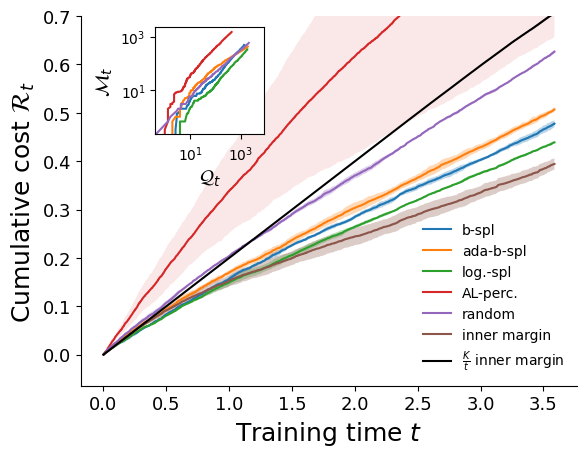

In [327]:
ax=plt.subplot(111)
line,=plt.plot(ts,R_C.mean(0)/d,   label="b-spl")
plt.fill_between(ts, R_C.mean(0)/d-R_C.std(0)/d, R_C.mean(0)/d+R_C.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.3)


line,=plt.plot(ts,R_C3.mean(0)/d,  label="ada-b-spl")
plt.fill_between(ts, R_C3.mean(0)/d-R_C3.std(0)/d, R_C3.mean(0)/d+R_C3.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.3)


line,=plt.plot(ts,R_S.mean(0)/d, label="log.-spl")
plt.fill_between(ts, R_S.mean(0)/d-R_S.std(0)/d, R_S.mean(0)/d+R_S.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.3)

line,=plt.plot(ts[1:],R_D.mean(0)/d,  label="AL-perc.")
plt.fill_between(ts[1:], R_D.mean(0)/d-R_D.std(0)/d, R_D.mean(0)/d+R_D.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.1)


line,=plt.plot(ts,R_P.mean(0)/d,   label="random")
plt.fill_between(ts, R_P.mean(0)/d-R_P.std(0)/d, R_P.mean(0)/d+R_P.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.3)

line,=plt.plot(ts,R_i.mean(0)/d,   label="inner margin")
plt.fill_between(ts, R_i.mean(0)/d-R_i.std(0)/d, R_i.mean(0)/d+R_i.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.3)

line,=plt.plot(ts,R.mean(0)/d, c="black", label=r"$\frac{K}{t}$"+" inner margin")
plt.fill_between(ts, R.mean(0)/d-R.std(0)/d, R.mean(0)/d+R.std(0)/d,color='none', facecolor=line.get_color(), alpha=0.3)

ax.spines[['right', 'top']].set_visible(False)




axin=ax.inset_axes( [0.15, 0.68, 0.22, 0.29])

axin.plot(Q_C.mean(0),M_C.mean(0),   label="b-spl")

axin.plot(Q_C3.mean(0),M_C3.mean(0),   label="b-spl")
axin.plot(Q_S.mean(0),M_S.mean(0),   label="b-spl")
axin.plot(Q_D.mean(0),M_D.mean(0),   label="b-spl")
axin.plot(Q_P.mean(0),M_P.mean(0),   label="b-spl")
axin.plot(Q.mean(0),M.mean(0), c="black", label=r"$p^\ast$")

axin.set_xscale("log")
axin.set_yscale("log")
#axin.set_ylim(0, 200)
axin.set_xlabel(r"$\mathcal{Q}_t$", fontsize=14)
axin.set_ylabel(r"$\mathcal{M}_t$", fontsize=14)
plt.ylim(top=.7)


plt.legend(frameon=False, loc=4, fontsize=10)

ax.tick_params(labelsize=13)
if Δ!=0.2: plt.title(r"$\Delta={}$".format(Δ), fontsize=18)


plt.xlabel("Training time "+ r"$t$", fontsize=18)
plt.ylabel("Cumulative cost "+ r"$\mathcal{R}_t$", fontsize=18)
